In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(r"C:\Users\DIACO\Desktop")

print("کتابخانه‌ها با موفقیت بارگذاری شدند.")

کتابخانه‌ها با موفقیت بارگذاری شدند.


In [28]:
books = pd.read_csv(
    DATA_DIR / 'BX-Books.csv', 
    sep=';', 
    encoding='latin-1', 
    on_bad_lines='skip', 
    low_memory=False
)

users = pd.read_csv(
    DATA_DIR / 'BX-Users.csv', 
    sep=';', 
    encoding='latin-1', 
    on_bad_lines='skip'
)

ratings = pd.read_csv(
    DATA_DIR / 'BX-Book-Ratings.csv', 
    sep=';', 
    encoding='latin-1', 
    on_bad_lines='skip'
)

print(f"کتاب‌ها: {books.shape}")
print(f"کاربران: {users.shape}")
print(f"امتیازها: {ratings.shape}")

کتاب‌ها: (271360, 8)
کاربران: (278858, 3)
امتیازها: (1149780, 3)


In [29]:
explicit_ratings = ratings[ratings['Book-Rating'] > 0].copy()

min_ratings = 15
user_counts = explicit_ratings['User-ID'].value_counts()
book_counts = explicit_ratings['ISBN'].value_counts()

dense_ratings = explicit_ratings[
    explicit_ratings['User-ID'].isin(user_counts[user_counts >= min_ratings].index) &
    explicit_ratings['ISBN'].isin(book_counts[book_counts >= min_ratings].index)
].copy()

dense_books = books[books['ISBN'].isin(dense_ratings['ISBN'].unique())].copy()

print(f"تعداد نمرات فیلترشده: {dense_ratings.shape[0]}")
print(f"تعداد کتاب‌های فیلترشده: {dense_books.shape[0]}")
print(f"تعداد کاربران فعال: {dense_ratings['User-ID'].nunique()}")

تعداد نمرات فیلترشده: 63632
تعداد کتاب‌های فیلترشده: 3149
تعداد کاربران فعال: 4612


In [30]:
r_series = dense_ratings['Book-Rating']

print("--- شاخص‌های آمار توصیفی نمرات ---")
print(f"Mean (میانگین): {r_series.mean():.2f}")
print(f"Median (میانه): {r_series.median():.2f}")
print(f"Std (انحراف معیار): {r_series.std():.2f}")
print(f"Variance (واریانس): {r_series.var():.2f}")
print(f"IQR: {r_series.quantile(0.75) - r_series.quantile(0.25):.2f}")
print(f"Min: {r_series.min()} | Max: {r_series.max()}")

--- شاخص‌های آمار توصیفی نمرات ---
Mean (میانگین): 7.90
Median (میانه): 8.00
Std (انحراف معیار): 1.76
Variance (واریانس): 3.11
IQR: 2.00
Min: 1 | Max: 10


C:\Users\DIACO\AppData\Local\Temp\ipykernel_31388\33676026.py:24: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 0].boxplot(dense_ratings['Book-Rating'], vert=True, patch_artist=True,


تصویر eda_analysis.png با موفقیت ذخیره شد.


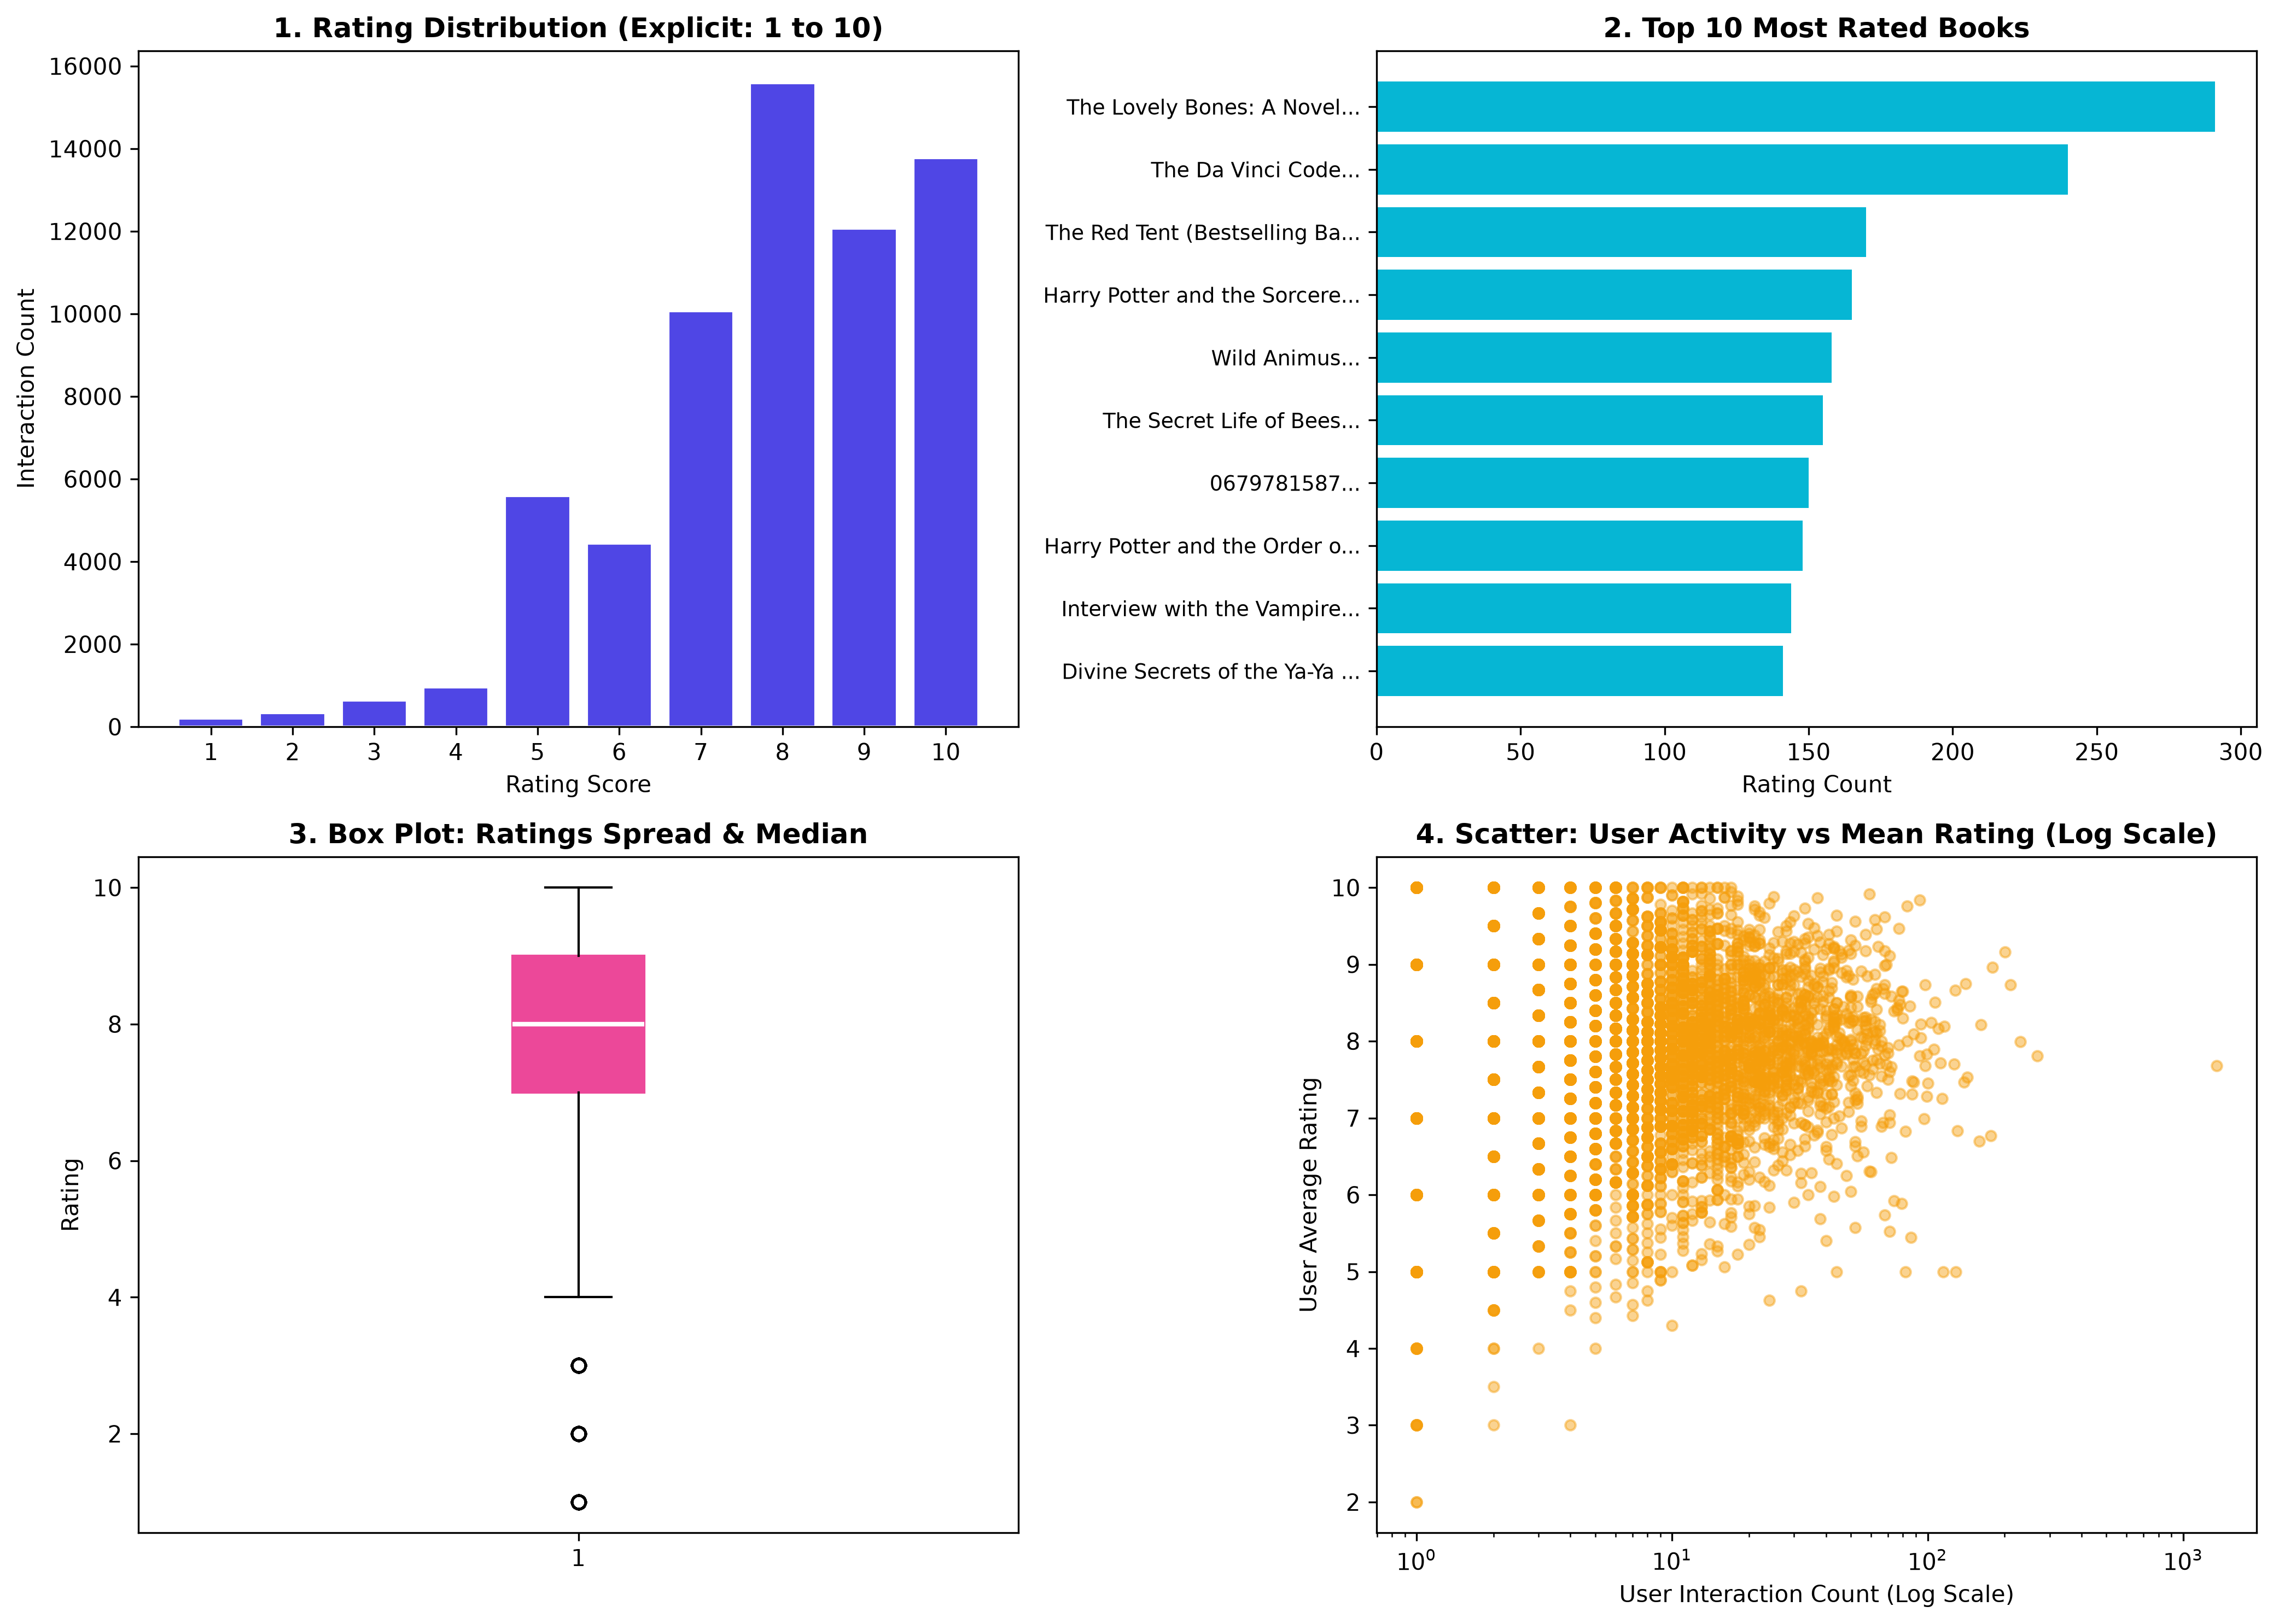

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

rating_counts = dense_ratings['Book-Rating'].value_counts().sort_index()
axes[0, 0].bar(rating_counts.index, rating_counts.values, color='#4f46e5', edgecolor='white', width=0.8)
axes[0, 0].set_title('1. Rating Distribution (Explicit: 1 to 10)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Rating Score')
axes[0, 0].set_ylabel('Interaction Count')
axes[0, 0].set_xticks(range(1, 11))

top_books_df = dense_ratings['ISBN'].value_counts().head(10).reset_index()
top_books_df.columns = ['ISBN', 'Rating_Count']

top_merged = top_books_df.merge(dense_books[['ISBN', 'Book-Title']].drop_duplicates(subset=['ISBN']), on='ISBN', how='left')
top_merged['Book-Title'] = top_merged['Book-Title'].fillna(top_merged['ISBN']).astype(str).str[:28] + '...'

y_pos = np.arange(len(top_merged))
axes[0, 1].barh(y_pos, top_merged['Rating_Count'].values, color='#06b6d4')
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(top_merged['Book-Title'].values, fontsize=9)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('2. Top 10 Most Rated Books', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Rating Count')

axes[1, 0].boxplot(dense_ratings['Book-Rating'], vert=True, patch_artist=True,
                  boxprops=dict(facecolor='#ec4899', color='#ec4899'),
                  medianprops=dict(color='white', linewidth=2))
axes[1, 0].set_title('3. Box Plot: Ratings Spread & Median', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Rating')

user_activity = dense_ratings.groupby('User-ID').agg({'Book-Rating': ['count', 'mean']})
user_activity.columns = ['activity_count', 'avg_rating']
axes[1, 1].scatter(user_activity['activity_count'], user_activity['avg_rating'], alpha=0.45, s=20, color='#f59e0b')
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('4. Scatter: User Activity vs Mean Rating (Log Scale)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('User Interaction Count (Log Scale)')
axes[1, 1].set_ylabel('User Average Rating')

plt.tight_layout()
plt.savefig('eda_analysis.png', dpi=300)
print("تصویر eda_analysis.png با موفقیت ذخیره شد.")
plt.show()

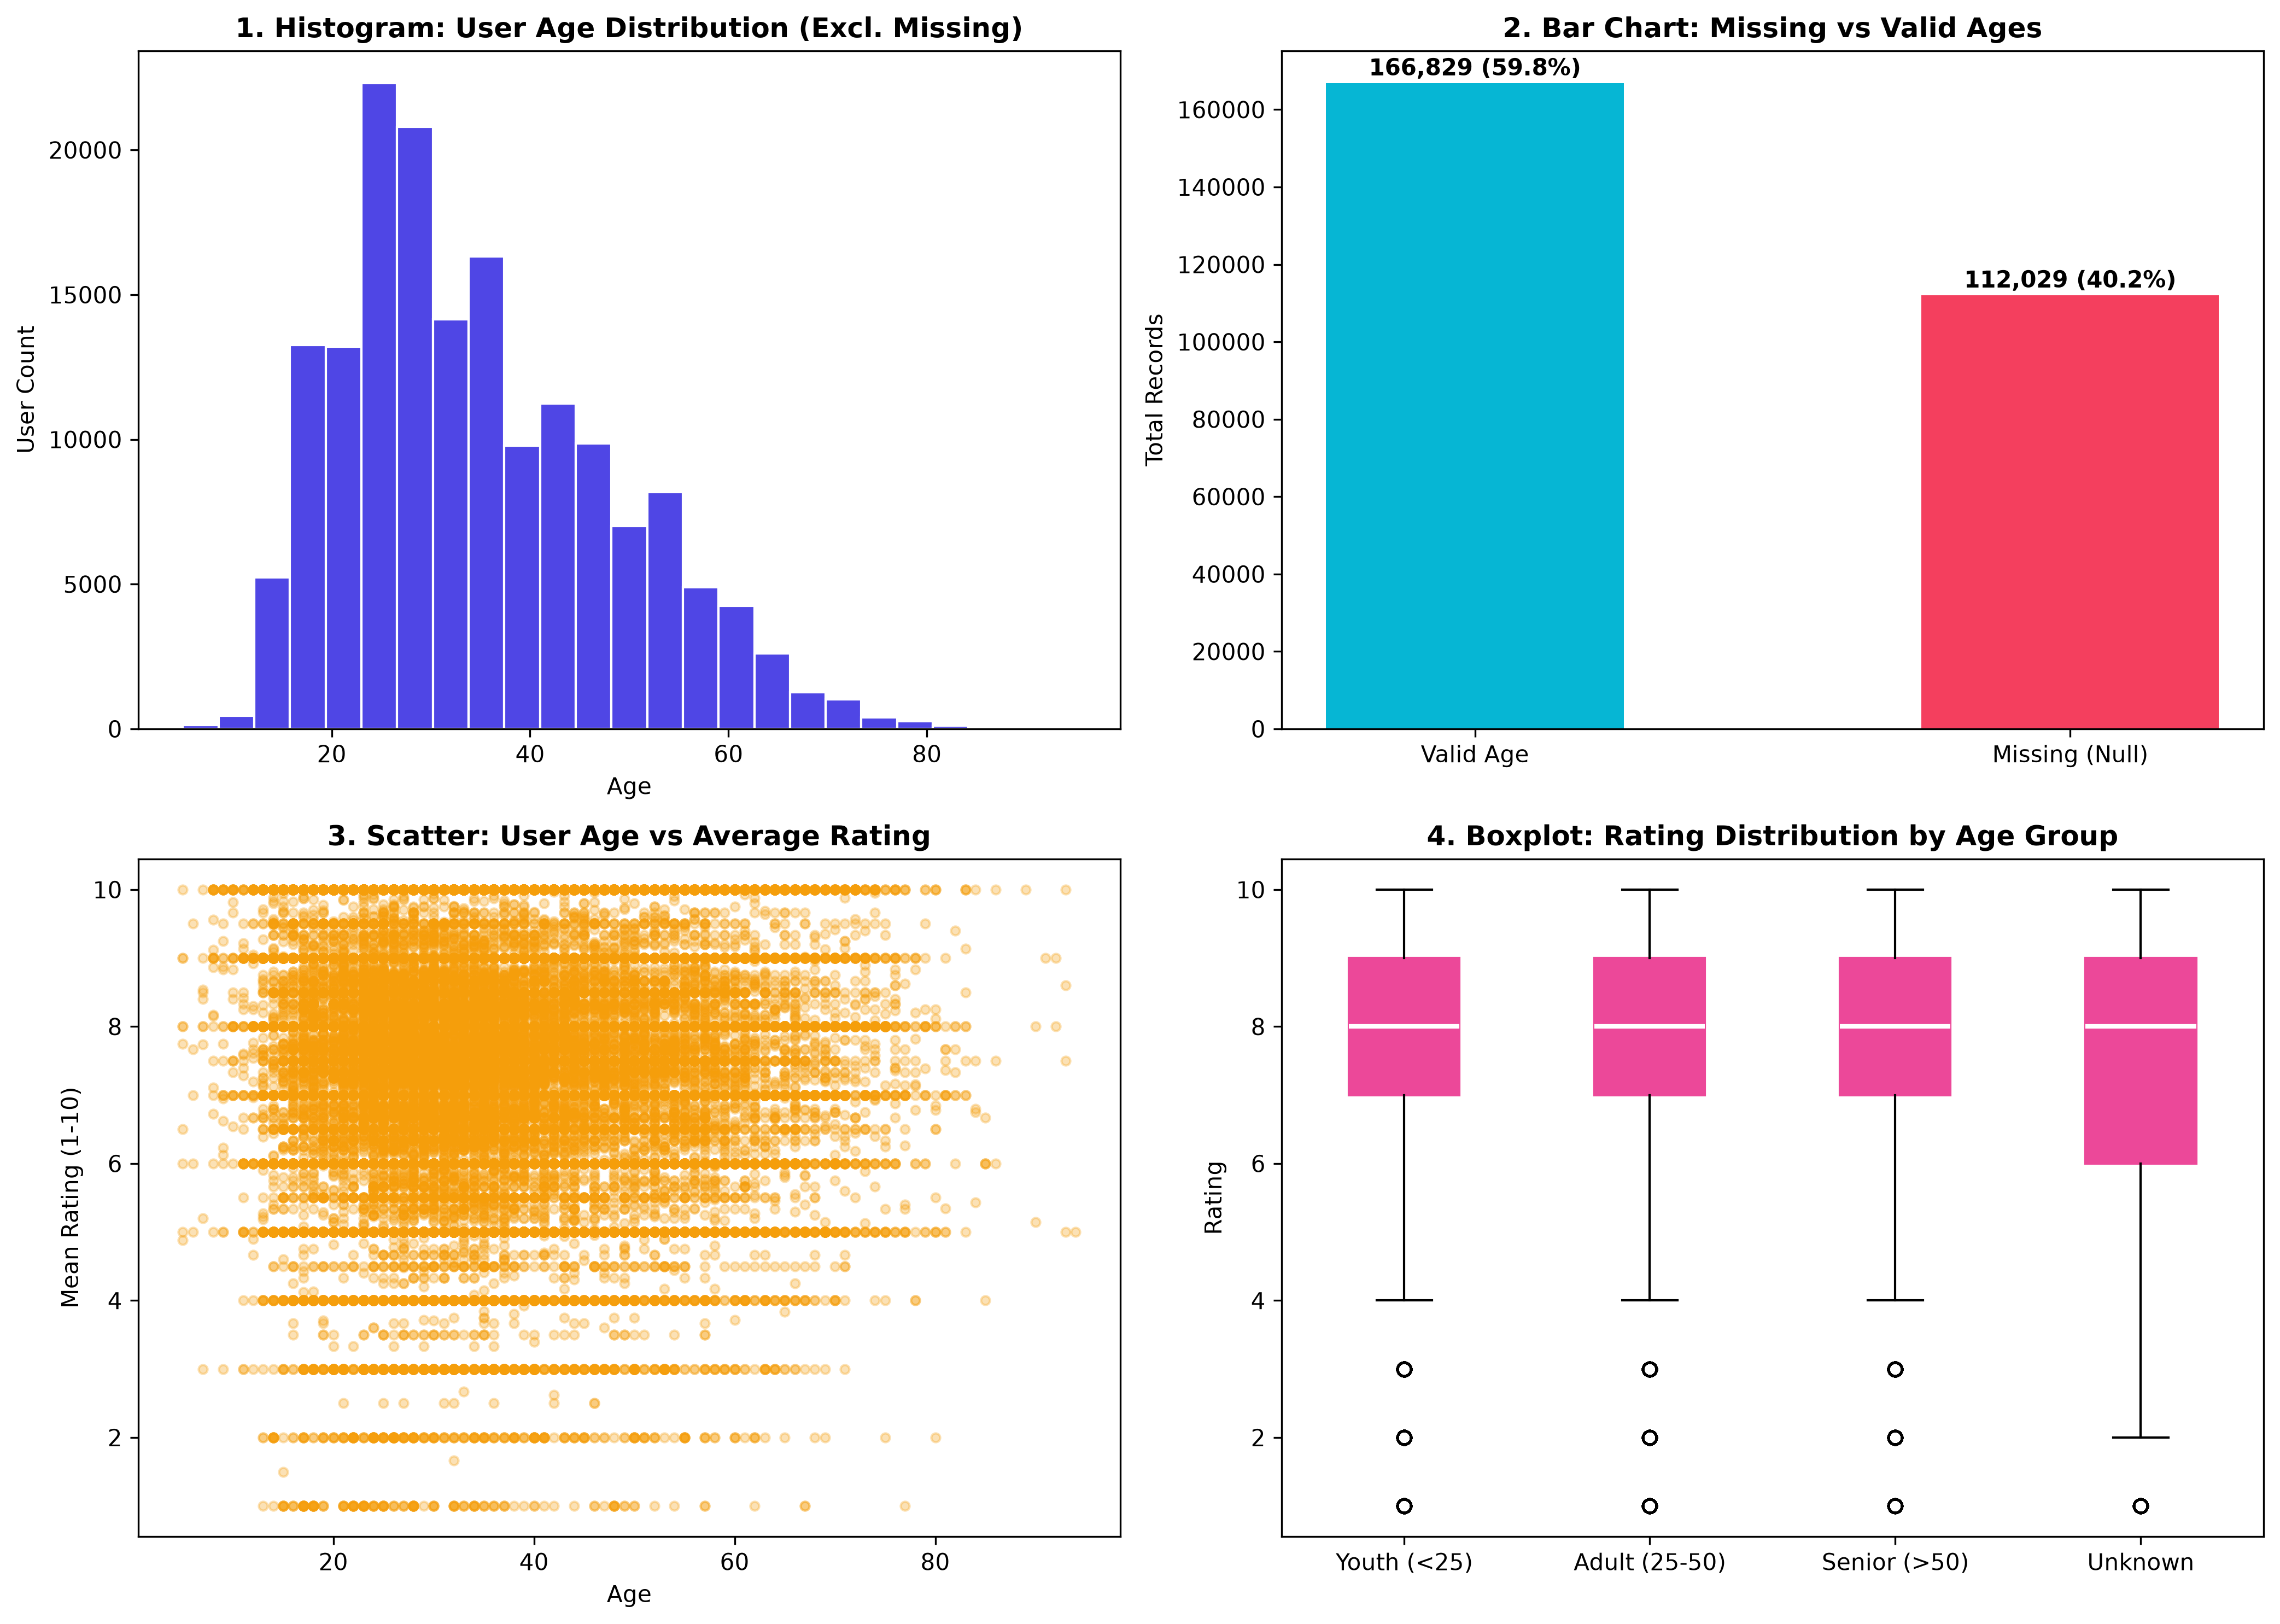

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(r"C:\Users\DIACO\Desktop")

users = pd.read_csv(DATA_DIR / 'BX-Users.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
ratings = pd.read_csv(DATA_DIR / 'BX-Book-Ratings.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
explicit_ratings = ratings[ratings['Book-Rating'] > 0]

valid_age_mask = (users['Age'] >= 5) & (users['Age'] <= 95)
users['Clean_Age'] = np.where(valid_age_mask, users['Age'], np.nan)

def categorize_age(age):
    if pd.isna(age):
        return 'Unknown'
    elif age < 25:
        return 'Youth (<25)'
    elif age <= 50:
        return 'Adult (25-50)'
    else:
        return 'Senior (>50)'

users['Age_Group'] = users['Clean_Age'].apply(categorize_age)

user_ratings = explicit_ratings.merge(users, on='User-ID', how='inner')

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

valid_ages = users['Clean_Age'].dropna()
axes[0, 0].hist(valid_ages, bins=25, color='#4f46e5', edgecolor='white')
axes[0, 0].set_title('1. Histogram: User Age Distribution (Excl. Missing)', fontweight='bold')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('User Count')

missing_counts = pd.Series({
    'Valid Age': users['Clean_Age'].notna().sum(),
    'Missing (Null)': users['Clean_Age'].isna().sum()
})
axes[0, 1].bar(missing_counts.index, missing_counts.values, color=['#06b6d4', '#f43f5e'], width=0.5)
axes[0, 1].set_title('2. Bar Chart: Missing vs Valid Ages', fontweight='bold')
axes[0, 1].set_ylabel('Total Records')
for i, v in enumerate(missing_counts.values):
    axes[0, 1].text(i, v + 2000, f"{v:,} ({(v/len(users))*100:.1f}%)", ha='center', fontweight='bold')

user_age_rating = user_ratings.dropna(subset=['Clean_Age']).groupby('User-ID').agg({'Clean_Age': 'first', 'Book-Rating': 'mean'})
axes[1, 0].scatter(user_age_rating['Clean_Age'], user_age_rating['Book-Rating'], alpha=0.3, s=15, color='#f59e0b')
axes[1, 0].set_title('3. Scatter: User Age vs Average Rating', fontweight='bold')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Mean Rating (1-10)')

groups = ['Youth (<25)', 'Adult (25-50)', 'Senior (>50)', 'Unknown']
box_data = [user_ratings[user_ratings['Age_Group'] == g]['Book-Rating'] for g in groups]
axes[1, 1].boxplot(box_data, tick_labels=groups, patch_artist=True,
                  boxprops=dict(facecolor='#ec4899', color='#ec4899'),
                  medianprops=dict(color='white', linewidth=2))
axes[1, 1].set_title('4. Boxplot: Rating Distribution by Age Group', fontweight='bold')
axes[1, 1].set_ylabel('Rating')

plt.tight_layout()
plt.savefig('age_eda_analysis.png', dpi=300)
plt.show()